In [20]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:

# %%
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import json
import os
from datetime import datetime
from pathlib import Path

# from dualwcfm.trainers.dual_trainer import DualTrainer, DualTrainerConfig
# from dualwcfm.visualization import plot_2d_flow_trajectories
# from dualwcfm.models.cfm import ConditionalFlowMatching
# from dualwcfm.trainers.dynamic_trainer import DynamicTrainer
# from dualwcfm.models.cfm import torch_wrapper
# from dualwcfm.trainers.wcfm import CFMTrainerConfig
from torchcfm.models.models import MLP
from dualwcfm.distributions.distribution import Distribution
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution
from dualwcfm.distributions import CouplingDistribution, RotatedShapeCoupling, Simple2DGaussianDistribution, RotatedDistribution, MoonDistribution
from dualwcfm.visualizer import plot_2d_flow_trajectories
from dualwcfm.cfm import ConditionalFlowMatching
from dualwcfm.distributions.distribution import Distribution, FixedSizeDistribution

# %%
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# %%
import torch
import torch.nn as nn
from torchdyn.core import NeuralODE

class LagrangianFlowField(nn.Module):
    """
    Wraps a velocity network to handle 'Source Conditioning'.
    State z = [x_t, x_0] (Dimension 2*D)
    Dynamics: dx/dt = net(x_t, x_0, t), dx_0/dt = 0
    """
    def __init__(self, net, dim):
        super().__init__()
        self.net = net
        self.dim = dim

    def forward(self, x):
        x_t = x[:, :self.dim]      # Current Position (Evolving)
        x_0 = x[:, self.dim:2*self.dim]      # Initial Position (Constant Context)

        v_x = self.net(x)
        v_c = torch.zeros_like(x_0)
        return torch.cat([v_x, v_c], dim=1)


In [22]:

# %%
def anticorrelate(n: int):
    source_samples = torch.randn(n, 2) * 0.5
    return source_samples, -source_samples

def create_distributions(device):
    """Create and return all distributions for the experiment."""
    coupling_dist = FunctionalCouplingDistribution(anticorrelate)
    source_dist, target_dist = coupling_dist.get_marginals()
    new_source_dist = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([1.0, 1.0]))
    new_target_dist = Simple2DGaussianDistribution(mean=torch.tensor([-5.0, -5.0]), std=torch.tensor([1.0, 1.0]))
    
    return {
        'coupling_dist': coupling_dist,
        'source_dist': source_dist,
        'target_dist': target_dist,
        'new_source_dist': new_source_dist,
        'new_target_dist': new_target_dist
    }

def plot_distributions(distributions, n_samples=2000):
    """Visualize all distributions."""
    coupling_dist = distributions['coupling_dist']
    new_source_dist = distributions['new_source_dist']
    new_target_dist = distributions['new_target_dist']
    
    coupling_samples = coupling_dist.coupling_sample(n_samples)
    source_samples = coupling_samples[0].cpu().numpy()
    target_samples = coupling_samples[1].cpu().numpy()
    new_source_samples = new_source_dist.sample(n_samples).cpu().numpy()
    new_target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    fig = plt.figure(figsize=(8, 8))
    plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
    plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
    plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
    plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
    plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=1.0, lw=0.6, label='Original Coupling')
    plt.title('Samples from Original and New Distributions')
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())
    plt.tight_layout()
    plt.show()


In [23]:
def interpolate(x0, x1, s, sigma):
    return (1 - s) * x0 + s * x1 + sigma * torch.randn_like(x0) * torch.sqrt(s * (1 - s))


In [24]:
class Experiment:
    """Encapsulates the entire training experiment with metrics and saving."""

    def __init__(self, config):
        self.config = config
        self.device = config.get("device", device)
        self.metrics = {
            "marginal_losses": {"mu": [], "nu": []},
            "dual_losses": [],
            "cfm_losses": {"mu": [], "nu": []},
            "coupling_errors": {"mse": [], "min": [], "max": []},
            "mass_conservation": [],
        }
        self.experiment_dir = None

    def setup_directories(self):
        """Create directories for saving experiment results."""
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        self.experiment_dir = Path(f"experiments/experiment_{timestamp}")
        self.experiment_dir.mkdir(parents=True, exist_ok=True)

        # Save config
        with open(self.experiment_dir / "config.json", "w") as f:
            json.dump(self.config, f, indent=2, default=str)

    def save_metrics(self):
        """Save metrics to file."""
        if self.experiment_dir:
            with open(self.experiment_dir / "metrics.json", "w") as f:
                json.dump(
                    self.metrics,
                    f,
                    indent=2,
                    default=lambda x: float(x) if isinstance(x, (torch.Tensor, np.generic)) else x,
                )

    def save_checkpoint(self, models, step):
        """Save model checkpoints."""
        if self.experiment_dir:
            checkpoint_dir = self.experiment_dir / "checkpoints"
            checkpoint_dir.mkdir(exist_ok=True)

            checkpoint = {
                "step": step,
                "models": {name: model.state_dict() for name, model in models.items()},
                "metrics": self.metrics,
            }
            torch.save(checkpoint, checkpoint_dir / f"checkpoint_step_{step}.pt")

            # Save latest
            torch.save(checkpoint, checkpoint_dir / "latest.pt")

    def plot_iteration_diagnostics(self, step, x_ref, y_ref, f_net, g_net, flow_model, device):
        """Visualizes the coupling, the learned weights, and the vector field."""
        x_ref_np = x_ref.detach().cpu().numpy()
        y_ref_np = y_ref.detach().cpu().numpy()
        with torch.no_grad():
            a = f_net(x_ref).view(-1)
            b = g_net(y_ref).view(-1)
            log_weights = a + b

        # Grid for vector field
        grid_n = 20
        x = np.linspace(-10, 10, grid_n)
        y = np.linspace(-10, 10, grid_n)
        X, Y = np.meshgrid(x, y)
        grid = torch.tensor(np.stack([X.flatten(), Y.flatten()], axis=1), dtype=torch.float32).to(device)

        # Flow Vector Field (at t=0 for this step)
        t_zeros = torch.zeros(grid.shape[0], 1).to(device)
        with torch.no_grad():
            vectors = flow_model(torch.cat([grid, grid, t_zeros], dim=1)).cpu().numpy()
            # vectors = flow_model(torch.cat([grid, torch.randn_like(grid), t_zeros], dim=1)).cpu().numpy()
        U = vectors[:, 0].reshape(grid_n, grid_n)
        V = vectors[:, 1].reshape(grid_n, grid_n)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        sc = axes[0].scatter(
            x_ref_np[:, 0], x_ref_np[:, 1], c=log_weights.cpu().numpy(), cmap="viridis", s=5, alpha=0.6
        )
        axes[0].set_title(f"Step {step}: Source Samples\n(Color = Log Learned Weight)")
        plt.colorbar(sc, ax=axes[0])
        axes[0].set_xlim(-10, 10)
        axes[0].set_ylim(-10, 10)

        axes[1].scatter(
            y_ref_np[:, 0], y_ref_np[:, 1], c=log_weights.cpu().numpy(), s=5, alpha=0.3, label="Target Coupling Y"
        )
        axes[1].set_title(f"Step {step}: Target Samples")
        axes[1].set_xlim(-10, 10)
        axes[1].set_ylim(-10, 10)

        axes[2].quiver(X, Y, U, V, color="blue", alpha=0.8)
        axes[2].set_title(f"Step {step}: Learned Flow Field (v_t)")
        axes[2].set_xlim(-10, 10)
        axes[2].set_ylim(-10, 10)

        plt.tight_layout()

        if self.experiment_dir:
            plt.savefig(self.experiment_dir / f"diagnostics_step_{step}.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

    def evaluate_coupling(self, x, y):
        """
        Evaluate the quality of generated coupling.
        For the anticorrelate function, ideal coupling should have y = -x.
        Returns various metrics.
        """
        with torch.no_grad():
            # MSE between y and -x (ideal coupling)
            mse = torch.mean((y + x) ** 2).item()

            # L1 distance
            l1 = torch.mean(torch.abs(y + x)).item()

            # Max error
            max_err = torch.max((y + x) ** 2).item()

            # Correlation (should be -1 for perfect anticorrelation)
            corr = torch.corrcoef(torch.stack([x.flatten(), y.flatten()]))[0, 1].item()

        return {"mse": mse, "l1": l1, "max_error": max_err, "correlation": corr}

    def print_mass_conservation_check(self, x, y, f_net, g_net, delta):
        """
        Checks if the learned potentials a(x) and b(y) naturally conserve mass.
        The goal is for the Net Mass Flux to be 0 (Mean Weight - 1 = 0).
        """
        with torch.no_grad():
            a = f_net(x)
            b = g_net(y)

            raw_log_w = (a + b) * delta
            raw_w = torch.exp(raw_log_w)
            mass_flux_error = raw_w.mean() - 1.0

            self.metrics["mass_conservation"].append(
                {
                    "mean_weight": raw_w.mean().item(),
                    "mass_flux_error": mass_flux_error.item(),
                    "step": len(self.metrics["mass_conservation"]),
                }
            )

        print(f"--- Mass Conservation Check ---")
        print(f"Mean Weight:       {raw_w.mean().item():.5f} (Target: 1.0)")
        print(f"Net Mass Flux:     {mass_flux_error.item():.5f} (Target: 0.0)")

    def train_marginal_cfm(self, distributions):
        """Train marginal conditional flow matching models."""
        print("Training marginal CFM...")

        flow_mu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(self.device)
        flow_nu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(self.device)

        optimizer_mu = optim.Adam(flow_mu.parameters(), lr=1e-3)
        optimizer_nu = optim.Adam(flow_nu.parameters(), lr=1e-3)
        loss_fn = nn.MSELoss()

        batch_size = self.config.get("batch_size", 2048)
        epochs_marginal = self.config.get("epochs_marginal", 2500)
        sigma = self.config.get("sigma", 0.1)

        def interpolate(x0, x1, t, sigma):
            return (1 - t) * x0 + t * x1 + sigma * torch.randn_like(x0) * torch.sqrt(t * (1 - t))

        pbar = trange(epochs_marginal, desc="Training Marginal Bridges")
        for epoch in pbar:
            x0, y0 = distributions["coupling_dist"].coupling_sample(batch_size)
            x1, y1 = distributions["new_source_dist"].sample(batch_size), distributions["new_target_dist"].sample(
                batch_size
            )
            x0, x1, y0, y1 = x0.to(self.device), x1.to(self.device), y0.to(self.device), y1.to(self.device)

            t = torch.rand(batch_size, 1).to(self.device)
            xt, yt = interpolate(x0, x1, t, sigma), interpolate(y0, y1, t, sigma)

            u_t, v_t = flow_mu(torch.cat([xt, t], dim=1)), flow_nu(torch.cat([yt, t], dim=1))
            target_u_t, target_v_t = x1 - x0, y1 - y0

            optimizer_mu.zero_grad()
            optimizer_nu.zero_grad()

            loss_mu = loss_fn(u_t, target_u_t)
            loss_mu.backward()
            optimizer_mu.step()

            loss_nu = loss_fn(v_t, target_v_t)
            loss_nu.backward()
            optimizer_nu.step()

            # Record metrics
            self.metrics["marginal_losses"]["mu"].append(loss_mu.item())
            self.metrics["marginal_losses"]["nu"].append(loss_nu.item())

            pbar.set_postfix({"Loss mu": loss_mu.item(), "Loss nu": loss_nu.item()})

        cfm_mu = ConditionalFlowMatching(
            distributions["source_dist"], distributions["new_source_dist"], flow_mu, sigma=sigma
        )
        cfm_nu = ConditionalFlowMatching(
            distributions["target_dist"], distributions["new_target_dist"], flow_nu, sigma=sigma
        )

        return cfm_mu, cfm_nu, flow_mu, flow_nu

    def run(self):
        """Main training loop."""
        print("Setting up experiment...")
        self.setup_directories()

        # Create distributions
        distributions = create_distributions(self.device)

        # Plot initial distributions
        plot_distributions(distributions)

        # Train marginal CFM
        cfm_mu, cfm_nu, flow_mu, flow_nu = self.train_marginal_cfm(distributions)

        # Visualize marginal CFM trajectories
        n_samples = 500
        n_timesteps = 20
        time = torch.linspace(0, 1, n_timesteps)

        traj_mu = cfm_mu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
        traj_nu = cfm_nu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
        target_mu_samples = distributions["new_source_dist"].sample(n_samples).cpu().numpy()
        target_nu_samples = distributions["new_target_dist"].sample(n_samples).cpu().numpy()

        plot_2d_flow_trajectories(
            trajectories=traj_mu,
            t=time,
            n_trajectories=n_samples,
            target_points=target_mu_samples,
            title=f"Flow Matching Trajectories for mu -> mu'",
        )
        plot_2d_flow_trajectories(
            trajectories=traj_nu,
            t=time,
            n_trajectories=n_samples,
            target_points=target_nu_samples,
            title=f"Flow Matching Trajectories for nu -> nu'",
        )

        # Main training parameters
        n_iterations = self.config.get("n_iterations", 100)
        epochs_dual_per_step = self.config.get("epochs_dual_per_step", 100)
        epochs_cfm_per_step = self.config.get("epochs_cfm_per_step", 250)
        delta = 1.0 / n_iterations
        dataset_size = self.config.get("dataset_size", 200_000)
        batch_size = self.config.get("batch_size", 2048)
        mode = self.config.get("mode", "implicit")
        sigma = self.config.get("sigma", 0.1)

        # Setup coupling distribution
        current_coupling_dist = FixedSizeCouplingDistribution(distributions["coupling_dist"], size=dataset_size)
        current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu()

        # Initialize networks
        f_net = MLP(dim=2, out_dim=1, w=16, time_varying=False).to(self.device)
        g_net = MLP(dim=2, out_dim=1, w=16, time_varying=False).to(self.device)
        flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(self.device)
        flow_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(self.device)
        previous_flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
        previous_flow_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True)

        # Optimizers
        optimizer_dual = optim.Adam(
            list(f_net.parameters()) + list(g_net.parameters()), lr=self.config.get("dual_lr", 1e-4)
        )
        cfm_optimizer_mu = optim.Adam(flow_model_mu.parameters(), lr=self.config.get("cfm_lr", 5e-3))
        cfm_optimizer_nu = optim.Adam(flow_model_nu.parameters(), lr=self.config.get("cfm_lr", 5e-3))

        # Initialize marginal distributions
        mu_dist, nu_dist = current_coupling_dist.get_marginals()
        mu_dist = FixedSizeDistribution(mu_dist, size=dataset_size)
        nu_dist = FixedSizeDistribution(nu_dist, size=dataset_size)

        flow_model_mu.to(device)
        flow_model_nu.to(device)

        pbar = trange(self.config.get("pretrained_epochs", 10000), desc="Pretraining CFM Models")
        for _ in pbar:
            x0, x1 = current_coupling_dist.coupling_sample(batch_size)
            x0, x1 = x0.to(device), x1.to(device)

            s = torch.rand(batch_size, 1).to(device)
            xs_mu = interpolate(x0, x1, s, sigma)
            xs_nu = interpolate(x1, x0, s, sigma)

            u_s_mu = flow_model_mu(torch.cat([xs_mu, x0, s], dim=1))
            u_s_nu = flow_model_nu(torch.cat([xs_nu, x1, s], dim=1))

            target_mu = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)
            target_nu = torch.cat([x0 - x1, torch.zeros_like(x0)], dim=1)
            loss_mu = ((u_s_mu - target_mu)**2).mean()
            loss_nu = ((u_s_nu - target_nu)**2).mean()

            cfm_optimizer_mu.zero_grad()
            loss_mu.backward()
            cfm_optimizer_mu.step()
            cfm_optimizer_nu.zero_grad()
            loss_nu.backward()
            cfm_optimizer_nu.step()
            pbar.set_postfix({"CFM Loss mu": loss_mu.item(), "CFM Loss nu": loss_nu.item()})

        # Training loop
        for step in range(n_iterations):
            t_current = step * delta
            t = torch.full((batch_size, 1), t_current).to(self.device)

            # Load previous models
            previous_flow_model_mu.load_state_dict(flow_model_mu.state_dict())
            previous_flow_model_nu.load_state_dict(flow_model_nu.state_dict())
            previous_flow_model_mu.to(self.device)
            previous_flow_model_nu.to(self.device)
            previous_flow_model_mu.eval()
            previous_flow_model_nu.eval()

            # Dual training
            f_net.train()
            g_net.train()

            pbar = trange(epochs_dual_per_step, desc=f"Dual Training Step {step}")
            for _ in pbar:
                x, y = current_coupling_dist.coupling_sample(batch_size)
                x_mu, y_nu = mu_dist.sample(batch_size).to(self.device), nu_dist.sample(batch_size).to(self.device)
                x, y = x.to(self.device), y.to(self.device)

                with torch.no_grad():
                    u_t = flow_mu(torch.cat([x_mu, t], dim=1))
                    v_t = flow_nu(torch.cat([y_nu, t], dim=1))

                x.requires_grad_(True)
                y.requires_grad_(True)
                x_mu.requires_grad_(True)
                y_nu.requires_grad_(True)

                a = f_net(x)
                b = g_net(y)
                a_mu = f_net(x_mu)
                b_nu = g_net(y_nu)

                # Loss computation
                term_coupling = torch.mean((a - a.mean() + b - b.mean()) ** 2)

                grad_a = torch.autograd.grad(a_mu.sum(), x_mu, create_graph=True, retain_graph=True, only_inputs=True)[
                    0
                ]
                grad_b = torch.autograd.grad(b_nu.sum(), y_nu, create_graph=True, retain_graph=True, only_inputs=True)[
                    0
                ]

                term_flow_a = torch.mean(torch.sum(grad_a * u_t, dim=1))
                term_flow_b = torch.mean(torch.sum(grad_b * v_t, dim=1))

                term_reg = 1e-3 * (torch.mean(a**2) + torch.mean(b**2)) + 1e-3 * (
                    torch.mean(a_mu**2) + torch.mean(b_nu**2)
                )

                gp_lambda = self.config.get("gp_lambda", 0.1)
                gp_f = ((grad_a.norm(2, dim=1) - 1) ** 2).mean()
                gp_g = ((grad_b.norm(2, dim=1) - 1) ** 2).mean()

                loss = 0.5 * term_coupling - term_flow_a - term_flow_b + term_reg + gp_lambda * (gp_f + gp_g)

                optimizer_dual.zero_grad()
                loss.backward()
                optimizer_dual.step()

                self.metrics["dual_losses"].append(loss.item())
                pbar.set_description(f"Dual Loss: {loss.item():.4f}")

            # CFM training
            flow_model_mu.train()
            flow_model_nu.train()
            f_net.eval()
            g_net.eval()

            pbar = trange(epochs_cfm_per_step, desc=f"CFM Training Step {step}")
            for epoch in pbar:
                x0, x1 = current_coupling_dist.coupling_sample(batch_size)
                x0, x1 = x0.to(self.device), x1.to(self.device)

                s = torch.rand(batch_size, 1).to(self.device)

                
                if step % 2 == 0:
                    xs = interpolate(x0, x1, s, sigma)
                    u_s_full = flow_model_mu(torch.cat([xs, x0, s], dim=1))
                    u_s = u_s_full[:, :2]
                else:
                    xs = interpolate(x1, x0, s, sigma)
                    u_s_full = flow_model_nu(torch.cat([xs, x1, s], dim=1))
                    u_s = u_s_full[:, :2]

                with torch.no_grad():
                    a, b = f_net(x0), g_net(x1)
                    r = a + b
                    log_w = r * delta
                    weight = torch.exp(log_w)

                if mode == "weight":
                    schrodinger_u_s = (x1 - x0) if step % 2 == 0 else (x0 - x1)
                    target_u_s = torch.cat([schrodinger_u_s, torch.zeros_like(x0)], dim=1)
                    loss = (weight * (u_s_full - target_u_s) ** 2).mean()
                elif mode == "implicit":
                    with torch.no_grad():
                        b_hat_detached = u_s.detach()
                        if step % 2 == 0:
                            b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1))[:, :2]
                            target = x1 - x0
                        else:
                            b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1))[:, :2]
                            target = x0 - x1

                        itm_target = b_ta + (weight - 1.0) * (target - b_hat_detached)
                        full_target = torch.cat([itm_target, torch.zeros_like(x0)], dim=1)

                    loss = nn.functional.mse_loss(u_s_full, full_target)

                cfm_optimizer_mu.zero_grad()
                cfm_optimizer_nu.zero_grad()
                loss.backward()
                cfm_optimizer_mu.step()
                cfm_optimizer_nu.step()

                # Record CFM losses
                if step % 2 == 0:
                    self.metrics["cfm_losses"]["mu"].append(loss.item())
                else:
                    self.metrics["cfm_losses"]["nu"].append(loss.item())

                pbar.set_description(f"CFM Loss: {loss.item():.4f}")

            chunks = 100_000
            num_steps = 50
            dt = 1.0 / num_steps
            flow_mu.eval()
            flow_nu.eval()
            # cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
            cfm_mu = ConditionalFlowMatching(
                distributions["new_source_dist"], distributions["new_target_dist"], flow_model_mu, sigma=0
            )
            cfm_nu = ConditionalFlowMatching(
                distributions["new_target_dist"], distributions["new_source_dist"], flow_model_nu, sigma=0
            )
            with torch.no_grad():
                for i in trange(0, dataset_size, chunks):
                    samples = current_coupling_dist.dataset[:, i:i+chunks]
                    # x, y = samples[0].to(device), samples[1].to(device)
                    x_mu, y_nu = mu_dist.dataset[i:i+chunks].to(device), nu_dist.dataset[i:i+chunks].to(device)

                    t_tensor = torch.full((x_mu.shape[0], 1), t_current).to(device)

                    x_mu_next = x_mu.detach() + delta * flow_mu(torch.cat([x_mu, t_tensor], dim=1))
                    y_nu_next = y_nu.detach() + delta * flow_nu(torch.cat([y_nu, t_tensor], dim=1))

                    if step % 2 == 0:
                        # x_next = x.detach() + delta * flow_mu(torch.cat([x, t_tensor], dim=1))
                        x_next = x_mu_next.detach().clone()

                        xt = x_next.clone()
                        for j in range(num_steps):
                            t = torch.ones(x_next.shape[0], 1).to(device) * (j * dt)
                            vt = flow_model_mu(torch.cat([xt, x_next, t], dim=1))[:, :2]
                            xt = xt + vt * dt
                        y_next = xt.clone()
                    else:
                        # y_next = y.detach() + delta * flow_nu(torch.cat([y, t_tensor], dim=1))
                        y_next = y_nu_next.detach().clone()

                        yt = y_next.clone()
                        for j in range(num_steps):
                            t = torch.ones(y_next.shape[0], 1).to(device) * (j * dt)
                            vt = flow_model_nu(torch.cat([yt, y_next, t], dim=1))[:, :2]
                            yt = yt + vt * dt
                        x_next = yt.clone()

                    x_next = x_next.detach().cpu()
                    y_next = y_next.detach().cpu()

                    current_coupling_dist.dataset[:, i:i+chunks] = torch.stack([x_next, y_next], dim=0)
                    mu_dist.dataset[i:i+chunks] = x_mu_next.detach().cpu()
                    nu_dist.dataset[i:i+chunks] = y_nu_next.detach().cpu()


            # Evaluation and visualization
            if step % 25 == 0 or step == n_iterations - 1:
                x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
                x_ref, y_ref = x_ref.to(self.device), y_ref.to(self.device)

                # Plot diagnostics
                self.plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model_mu, self.device)

                # Evaluate coupling
                coupling_metrics = self.evaluate_coupling(x_ref, y_ref)
                print(
                    f"Step {step}: Coupling Evaluation - MSE: {coupling_metrics['mse']:.4f}, "
                    f"L1: {coupling_metrics['l1']:.4f}, Corr: {coupling_metrics['correlation']:.4f}"
                )

                # Record coupling errors
                self.metrics["coupling_errors"]["mse"].append(coupling_metrics["mse"])
                self.metrics["coupling_errors"]["min"].append(coupling_metrics["l1"])  # Using L1 as min proxy
                self.metrics["coupling_errors"]["max"].append(coupling_metrics["max_error"])

                # Mass conservation check
                self.print_mass_conservation_check(x_ref, y_ref, f_net, g_net, delta)

                # Save checkpoint
                models = {
                    "f_net": f_net,
                    "g_net": g_net,
                    "flow_model_mu": flow_model_mu,
                    "flow_model_nu": flow_model_nu,
                    "flow_mu": flow_mu,
                    "flow_nu": flow_nu,
                }
                self.save_checkpoint(models, step)

                # Save metrics
                self.save_metrics()

        print("Training completed!")

        # Final visualization and metrics
        self.final_evaluation(distributions, f_net, g_net, flow_model_mu, flow_model_nu, current_coupling_dist)

        return {
            "models": {
                "f_net": f_net,
                "g_net": g_net,
                "flow_model_mu": flow_model_mu,
                "flow_model_nu": flow_model_nu,
                "flow_mu": flow_mu,
                "flow_nu": flow_nu,
            },
            "metrics": self.metrics,
            "experiment_dir": self.experiment_dir,
        }

    def final_evaluation(self, distributions, f_net, g_net, flow_model_mu, flow_model_nu, current_coupling_dist):
        """Final evaluation and visualization after training."""
        print("Performing final evaluation...")

        # Final coupling evaluation
        x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
        x_ref, y_ref = x_ref.to(self.device), y_ref.to(self.device)
        self.plot_iteration_diagnostics(
            len(self.metrics["coupling_errors"]["mse"]),
            x_ref,
            y_ref,
            f_net,
            g_net,
            flow_model_mu,
            self.device,
        )

        # Visualize learned W-CFM
        flow_model_mu.eval()
        with torch.no_grad():
            cfm = ConditionalFlowMatching(
                distributions["new_source_dist"], distributions["new_target_dist"], flow_model_mu, sigma=0
            )
            n_samples = 500
            n_timesteps = 50
            time = torch.linspace(0, 1, n_timesteps)
            x_init = distributions["new_source_dist"].sample(n_samples).to(self.device)
            x_init_extended = torch.cat([x_init, x_init], dim=1)
            traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
            target_samples = distributions["new_target_dist"].sample(n_samples).cpu().numpy()

            plot_2d_flow_trajectories(
                trajectories=traj,
                t=time,
                n_trajectories=n_samples,
                target_points=target_samples,
                title=f"Final W-CFM Trajectories",
            )
            plt.show()

        # Plot training curves
        self.plot_training_curves()

    def plot_training_curves(self):
        """Plot training loss curves."""
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        # Marginal losses
        axes[0, 0].plot(self.metrics["marginal_losses"]["mu"], label="mu", alpha=0.7)
        axes[0, 0].plot(self.metrics["marginal_losses"]["nu"], label="nu", alpha=0.7)
        axes[0, 0].set_title("Marginal CFM Losses")
        axes[0, 0].set_xlabel("Epoch")
        axes[0, 0].set_ylabel("Loss")
        axes[0, 0].legend()
        axes[0, 0].grid(True, alpha=0.3)

        # Dual losses
        axes[0, 1].plot(self.metrics["dual_losses"], label="Dual Loss", color="green", alpha=0.7)
        axes[0, 1].set_title("Dual Training Loss")
        axes[0, 1].set_xlabel("Iteration")
        axes[0, 1].set_ylabel("Loss")
        axes[0, 1].grid(True, alpha=0.3)

        # CFM losses
        axes[1, 0].plot(self.metrics["cfm_losses"]["mu"], label="mu", alpha=0.7)
        axes[1, 0].plot(self.metrics["cfm_losses"]["nu"], label="nu", alpha=0.7)
        axes[1, 0].set_title("CFM Losses")
        axes[1, 0].set_xlabel("Iteration")
        axes[1, 0].set_ylabel("Loss")
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)

        # Coupling errors
        axes[1, 1].plot(self.metrics["coupling_errors"]["mse"], label="MSE", alpha=0.7)
        axes[1, 1].plot(self.metrics["coupling_errors"]["min"], label="Min Error", alpha=0.7)
        axes[1, 1].plot(self.metrics["coupling_errors"]["max"], label="Max Error", alpha=0.7)
        axes[1, 1].set_title("Coupling Errors")
        axes[1, 1].set_xlabel("Evaluation Step")
        axes[1, 1].set_ylabel("Error")
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()

        if self.experiment_dir:
            plt.savefig(self.experiment_dir / "training_curves.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

In [25]:
# Optional: Load and analyze saved experiment
def load_experiment(experiment_dir):
    """Load a saved experiment."""
    experiment_dir = Path(experiment_dir)

    # Load config
    with open(experiment_dir / "config.json", "r") as f:
        config = json.load(f)

    # Load metrics
    with open(experiment_dir / "metrics.json", "r") as f:
        metrics = json.load(f)

    # Load latest checkpoint
    checkpoint = torch.load(experiment_dir / "checkpoints" / "latest.pt")

    return {"config": config, "metrics": metrics, "checkpoint": checkpoint}


# Example usage:
# saved_experiment = load_experiment("experiments/experiment_20240101_120000")

Setting up experiment...


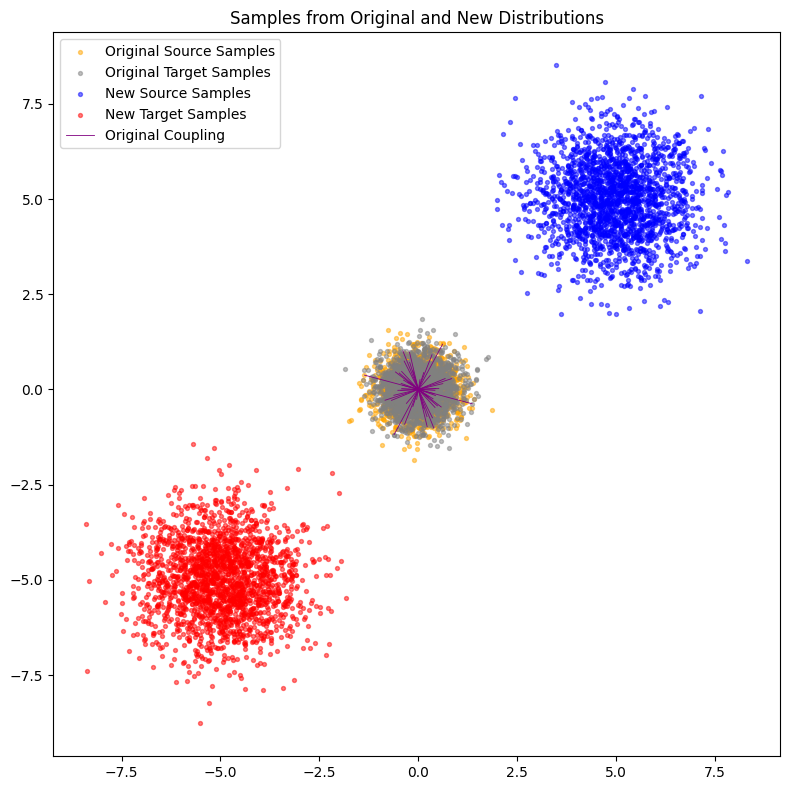

Training marginal CFM...


100%|██████████| 2/2 [00:00<00:00,  8.13it/s]


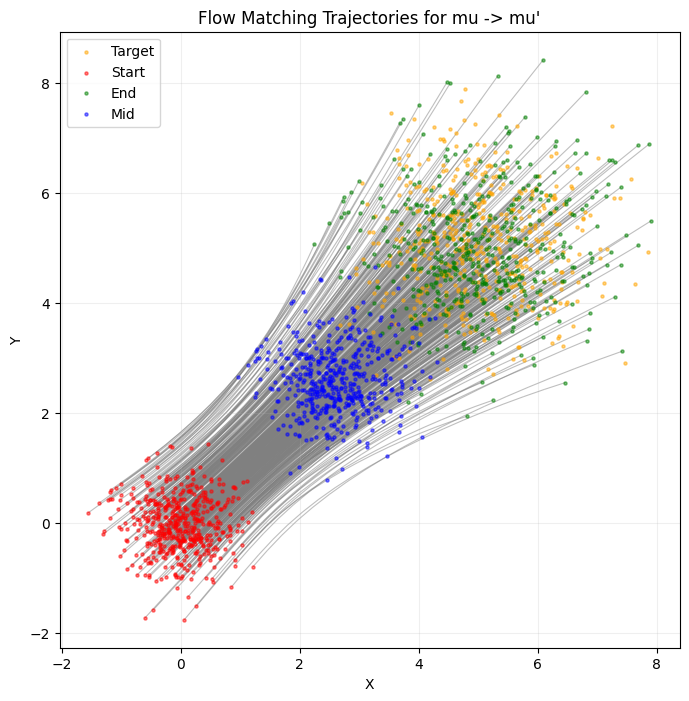

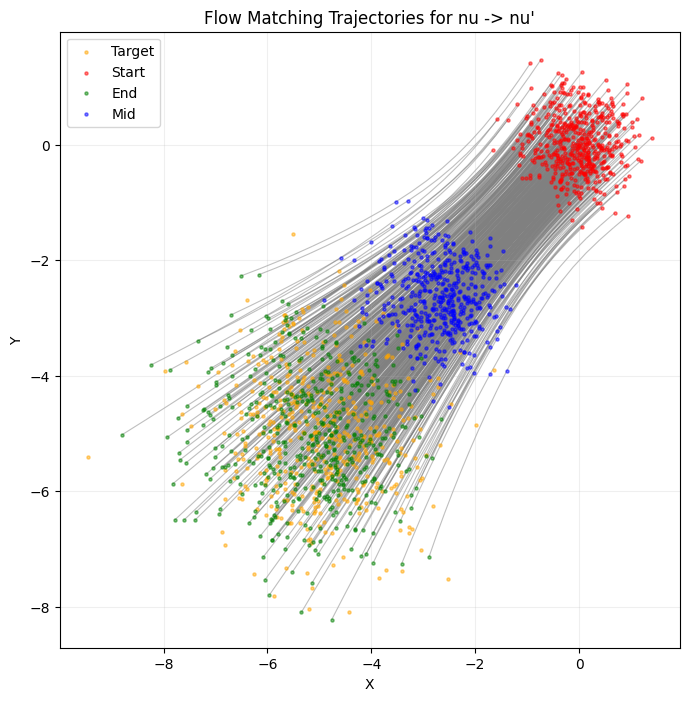

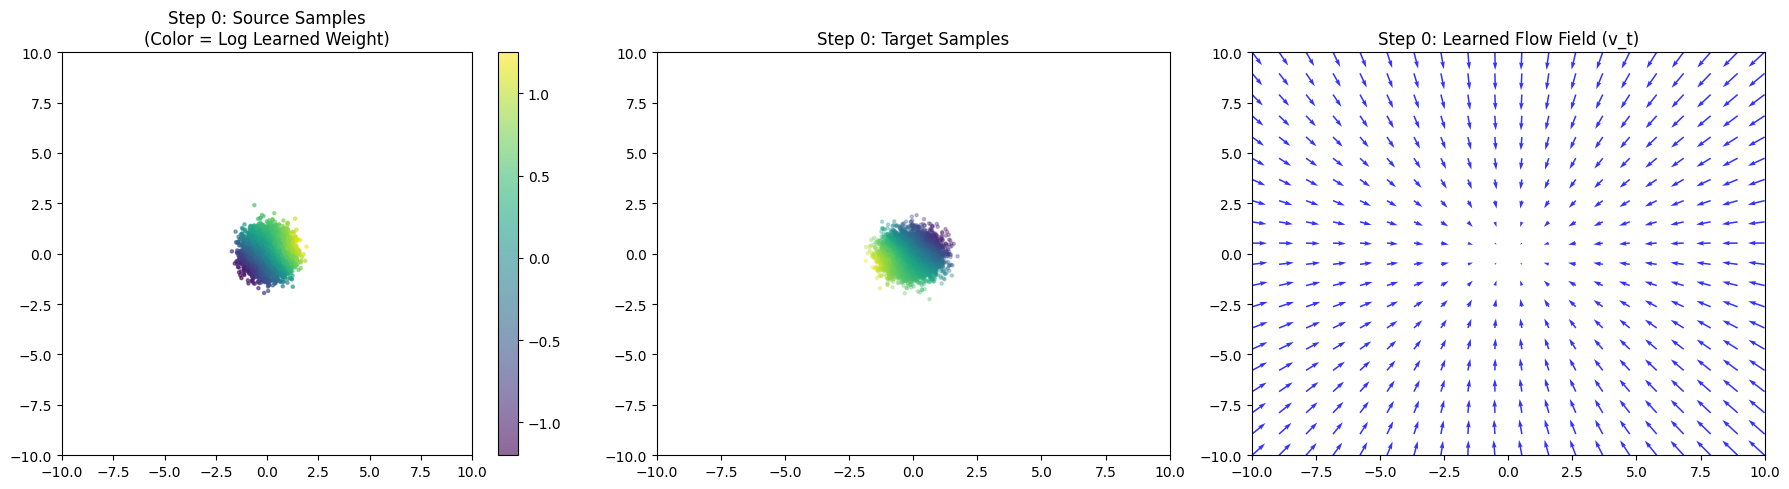

Step 0: Coupling Evaluation - MSE: 0.0000, L1: 0.0044, Corr: -1.0000
--- Mass Conservation Check ---
Mean Weight:       1.00100 (Target: 1.0)
Net Mass Flux:     0.00100 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00,  6.55it/s]


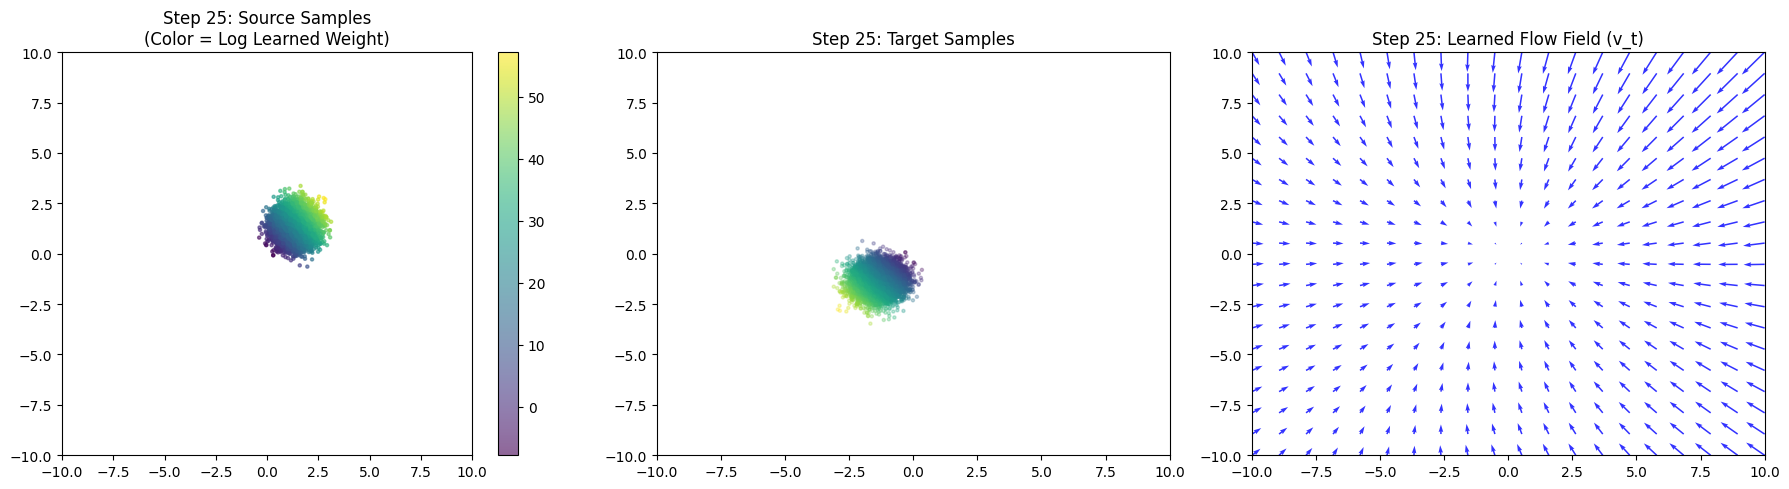

Step 25: Coupling Evaluation - MSE: 0.0009, L1: 0.0276, Corr: -0.9996
--- Mass Conservation Check ---
Mean Weight:       1.26010 (Target: 1.0)
Net Mass Flux:     0.26010 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00,  6.70it/s]


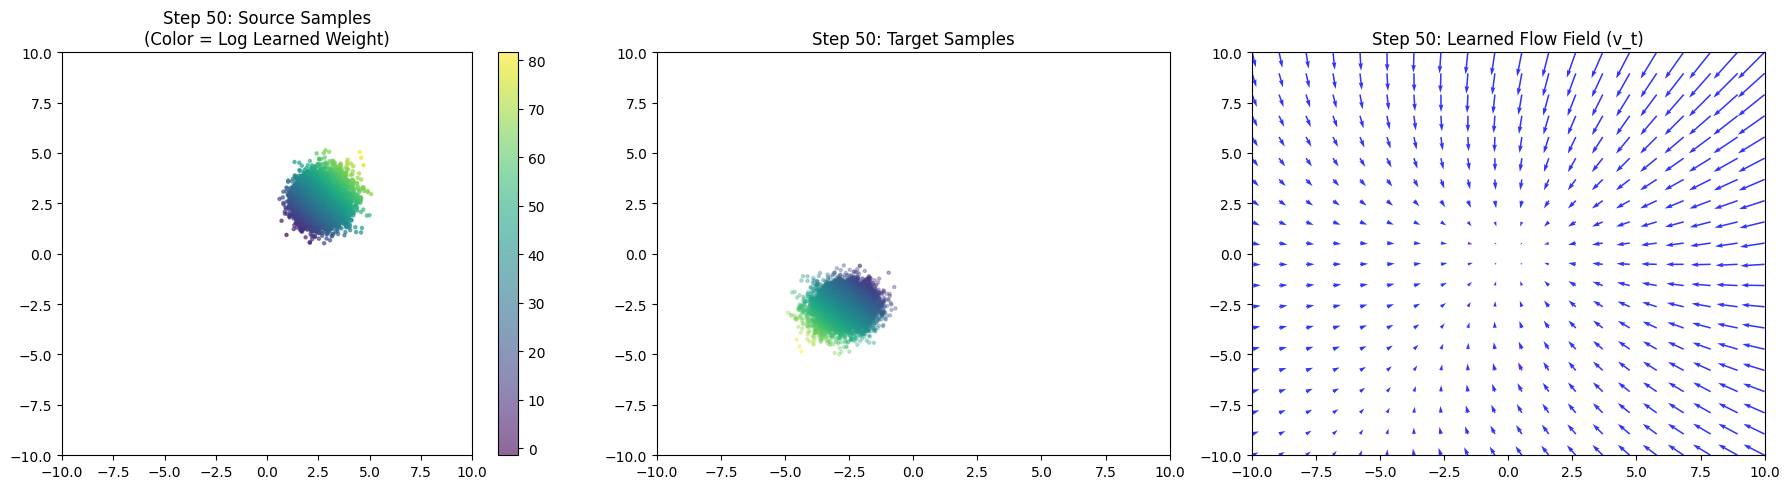

Step 50: Coupling Evaluation - MSE: 0.0029, L1: 0.0461, Corr: -0.9987
--- Mass Conservation Check ---
Mean Weight:       1.43333 (Target: 1.0)
Net Mass Flux:     0.43333 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00, 15.71it/s]


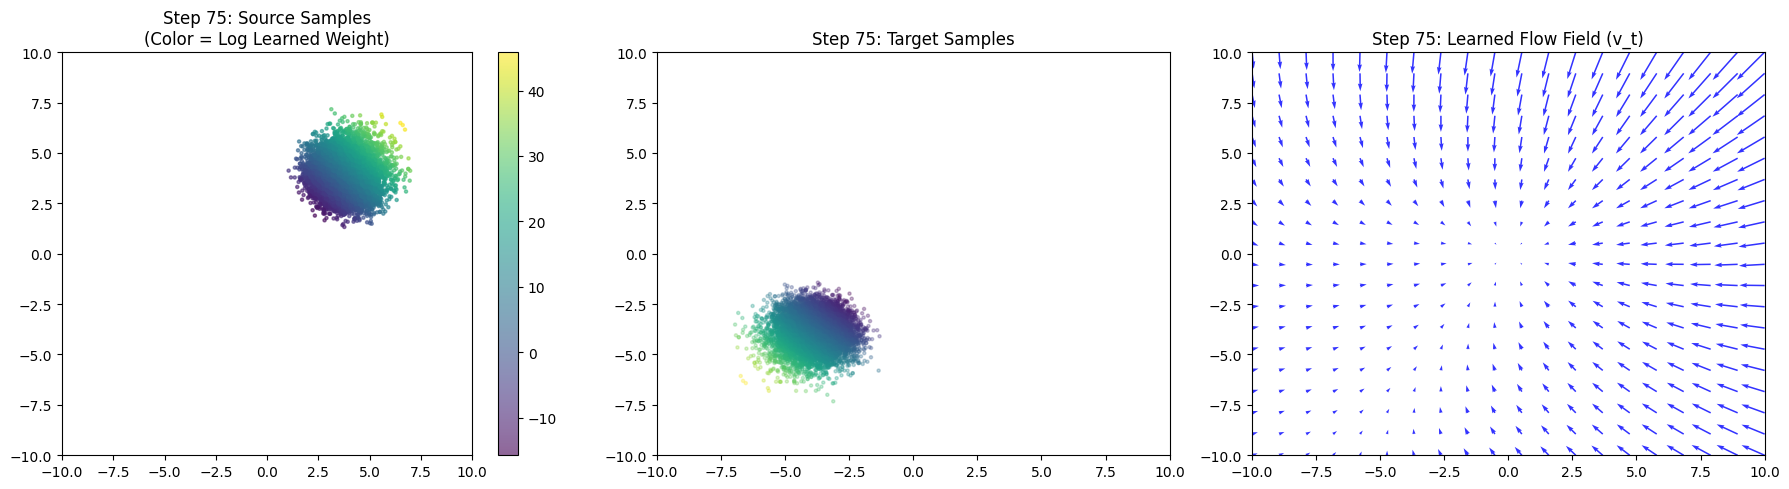

Step 75: Coupling Evaluation - MSE: 0.0096, L1: 0.0788, Corr: -0.9968
--- Mass Conservation Check ---
Mean Weight:       1.08276 (Target: 1.0)
Net Mass Flux:     0.08276 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00,  7.67it/s]


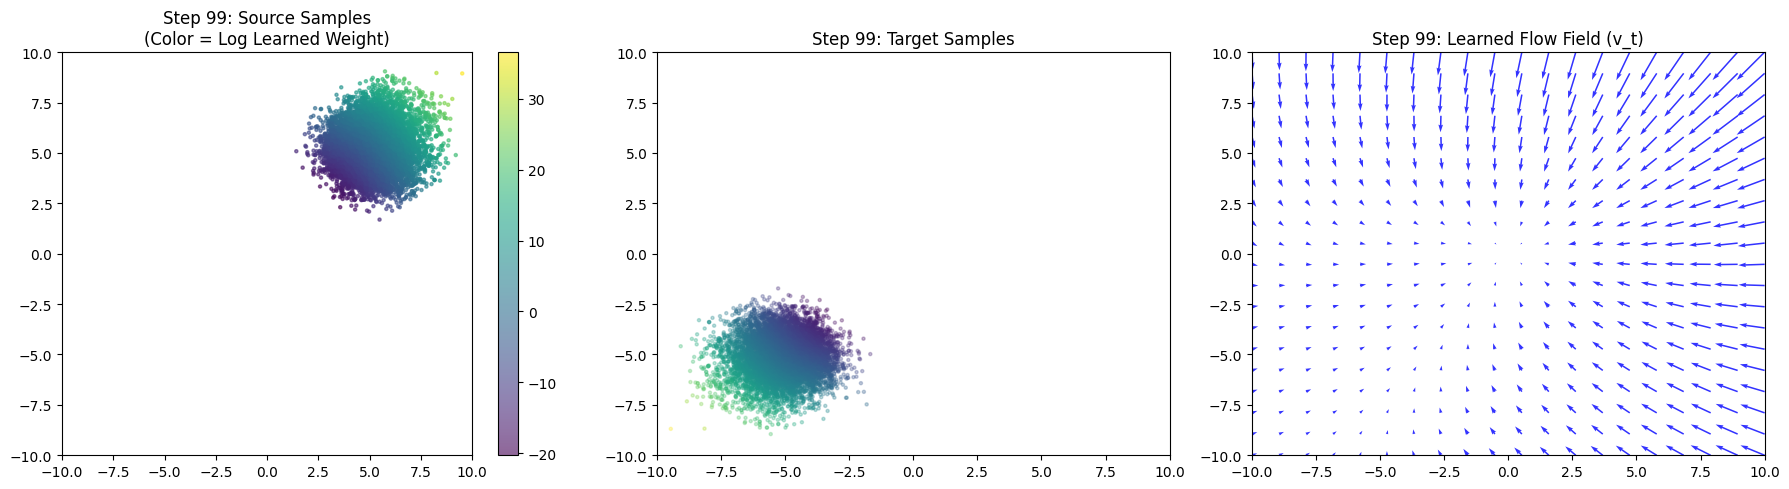

Step 99: Coupling Evaluation - MSE: 0.0186, L1: 0.1173, Corr: -0.9960
--- Mass Conservation Check ---
Mean Weight:       0.99595 (Target: 1.0)
Net Mass Flux:     -0.00405 (Target: 0.0)
Training completed!
Performing final evaluation...


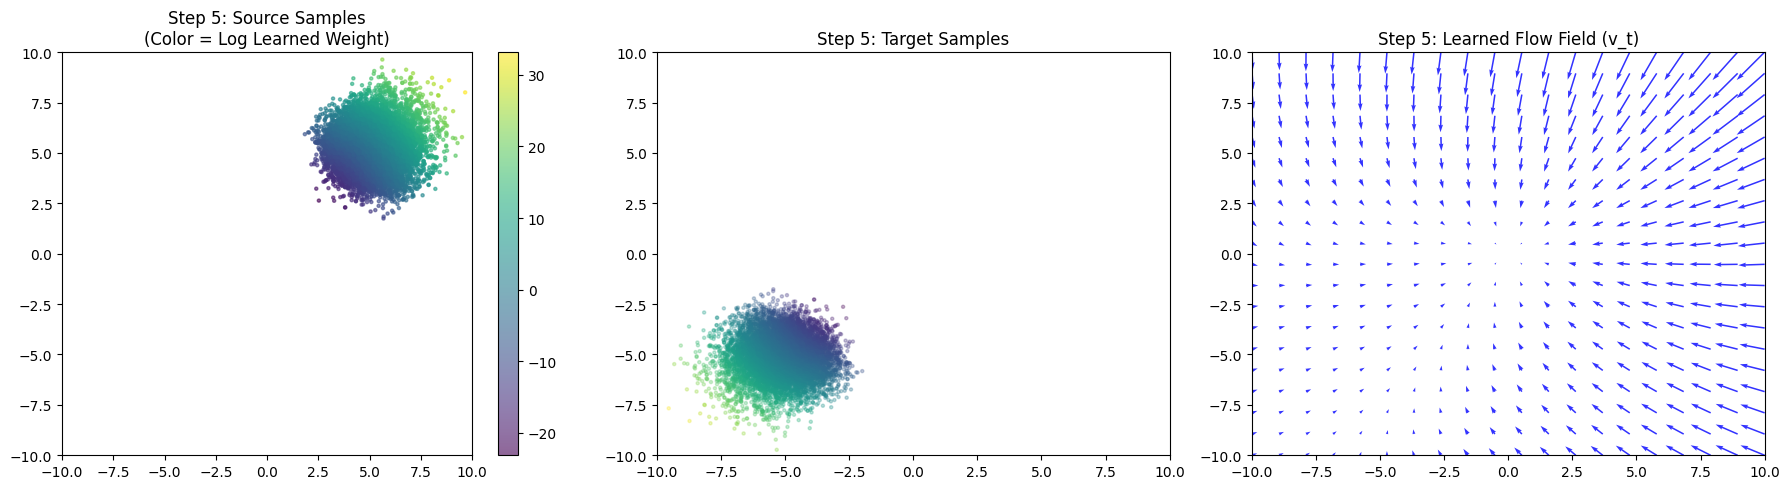

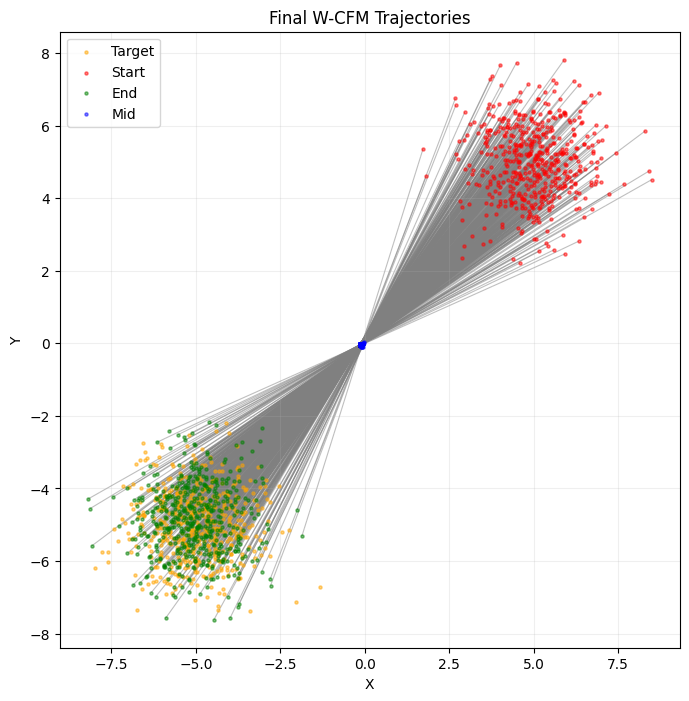

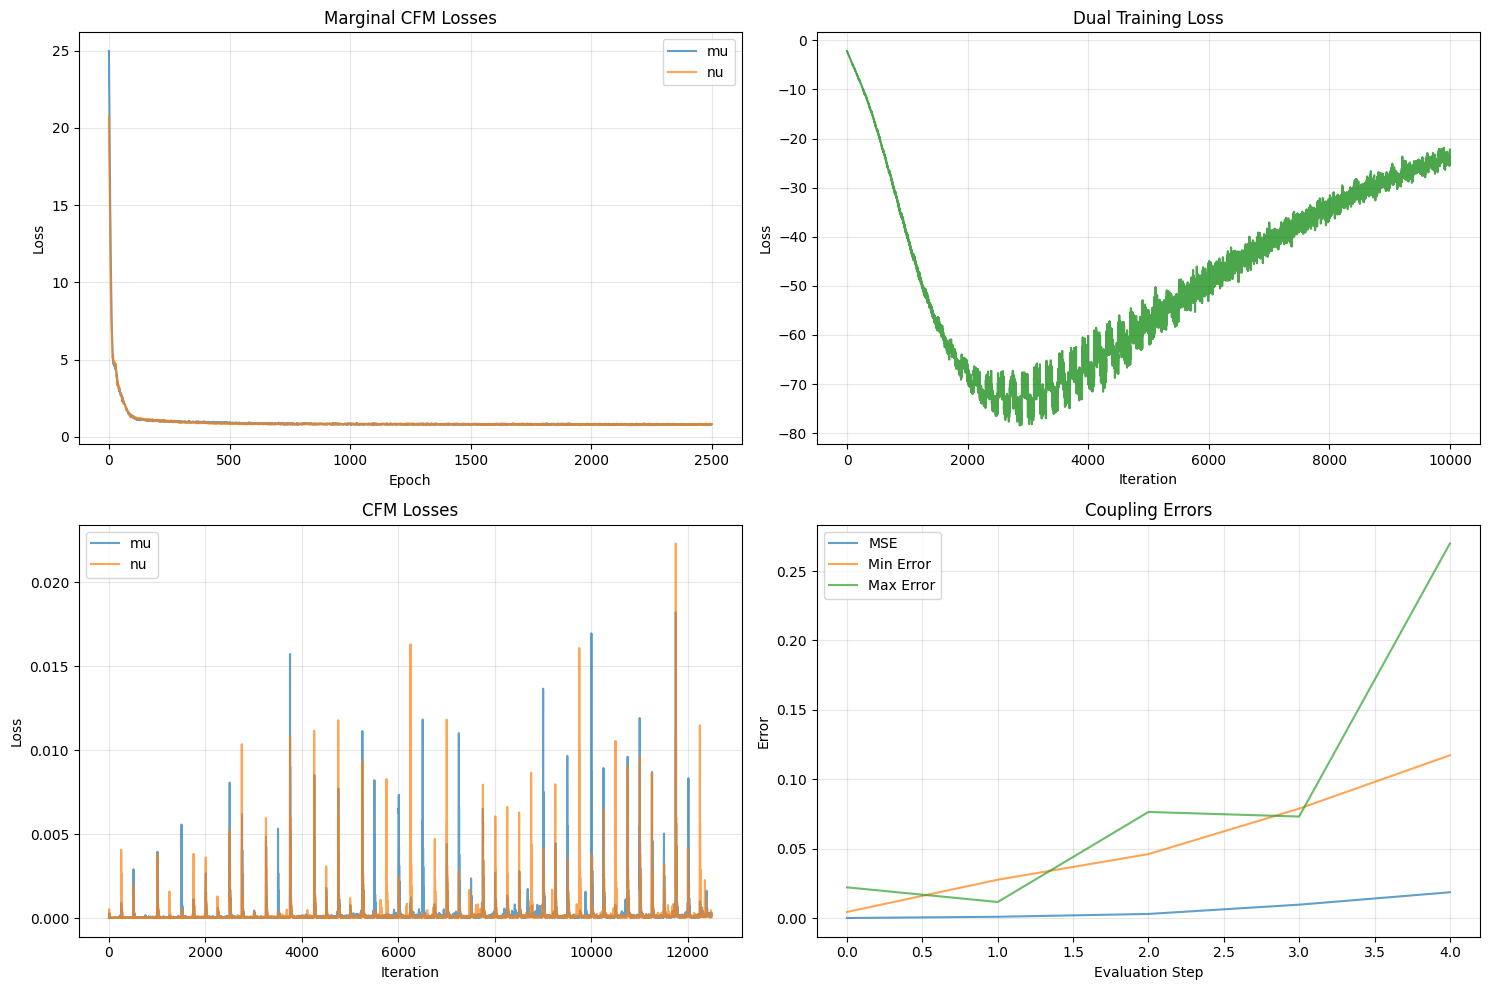

Setting up experiment...


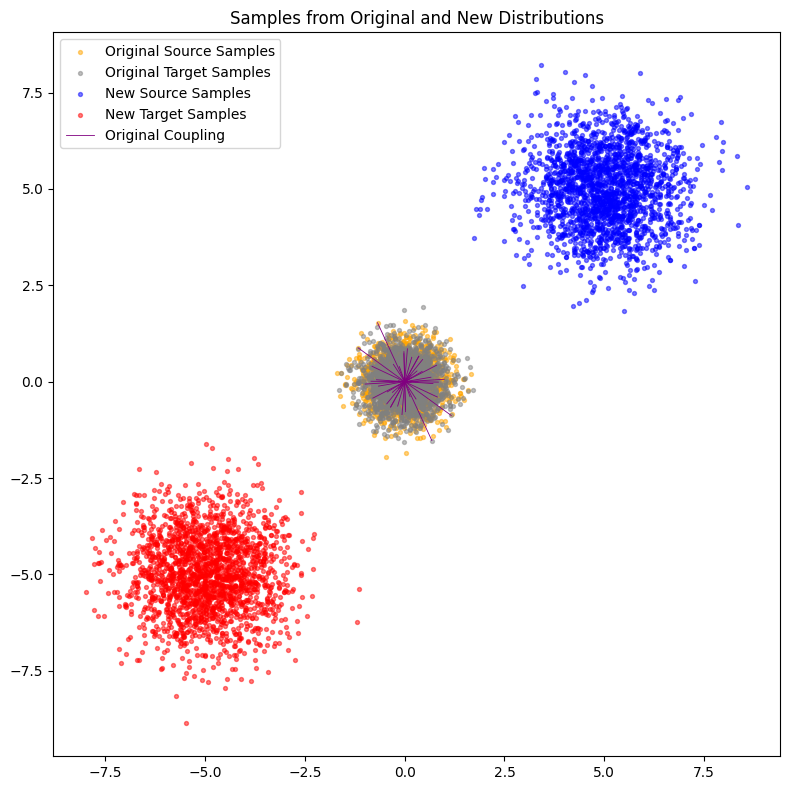

Training marginal CFM...


100%|██████████| 2/2 [00:00<00:00,  6.03it/s]


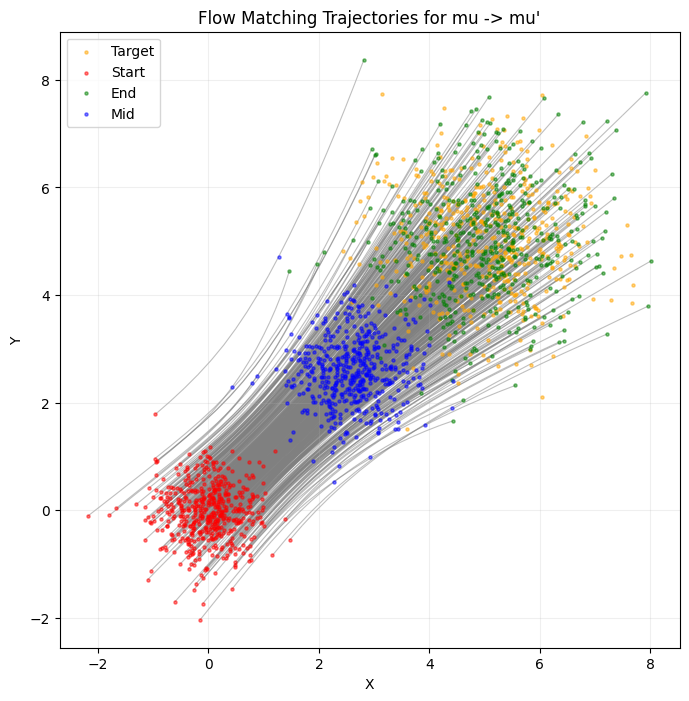

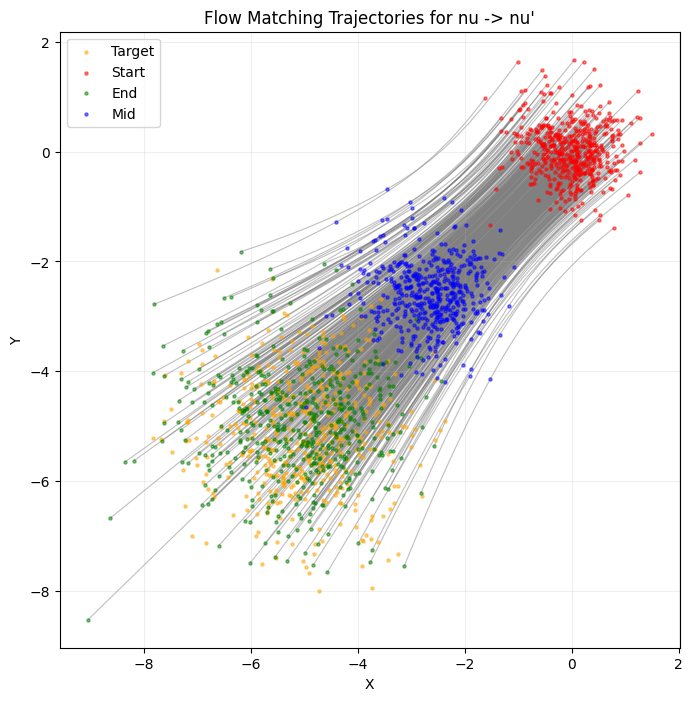

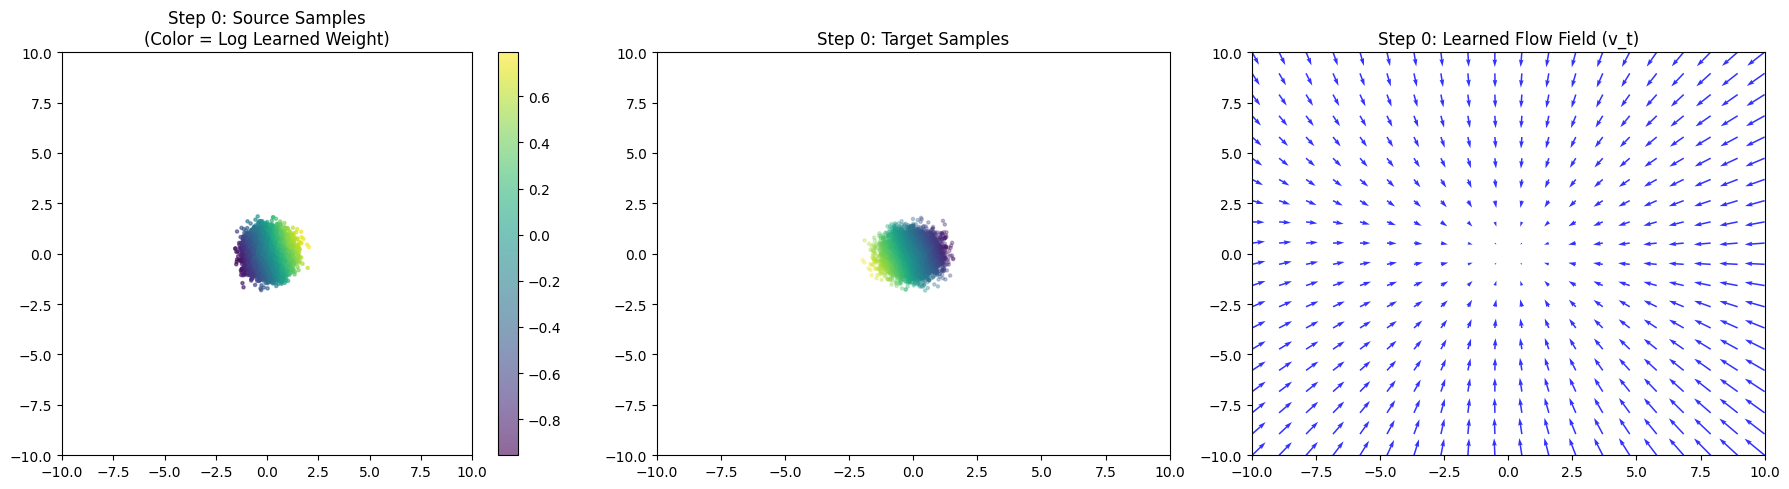

Step 0: Coupling Evaluation - MSE: 0.0000, L1: 0.0025, Corr: -1.0000
--- Mass Conservation Check ---
Mean Weight:       0.99887 (Target: 1.0)
Net Mass Flux:     -0.00113 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00,  7.57it/s]


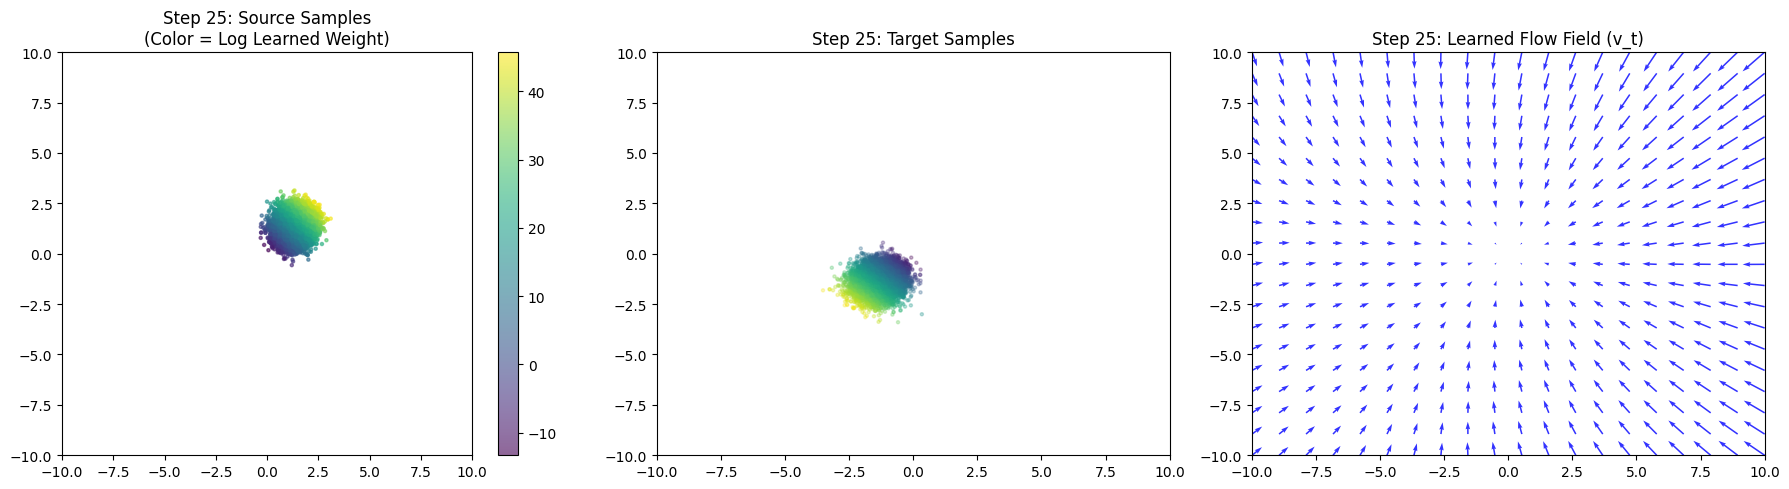

Step 25: Coupling Evaluation - MSE: 0.0003, L1: 0.0099, Corr: -0.9994
--- Mass Conservation Check ---
Mean Weight:       1.19159 (Target: 1.0)
Net Mass Flux:     0.19159 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00,  6.09it/s]


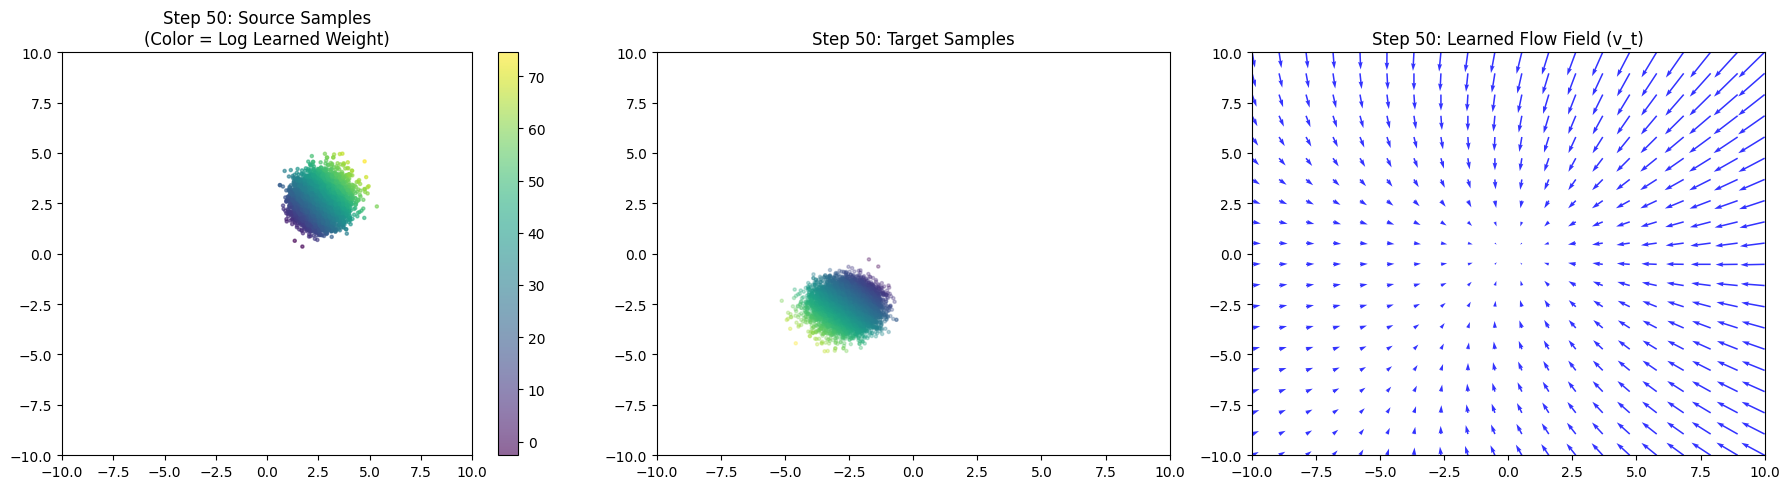

Step 50: Coupling Evaluation - MSE: 0.0012, L1: 0.0237, Corr: -0.9987
--- Mass Conservation Check ---
Mean Weight:       1.38393 (Target: 1.0)
Net Mass Flux:     0.38393 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00, 16.50it/s]


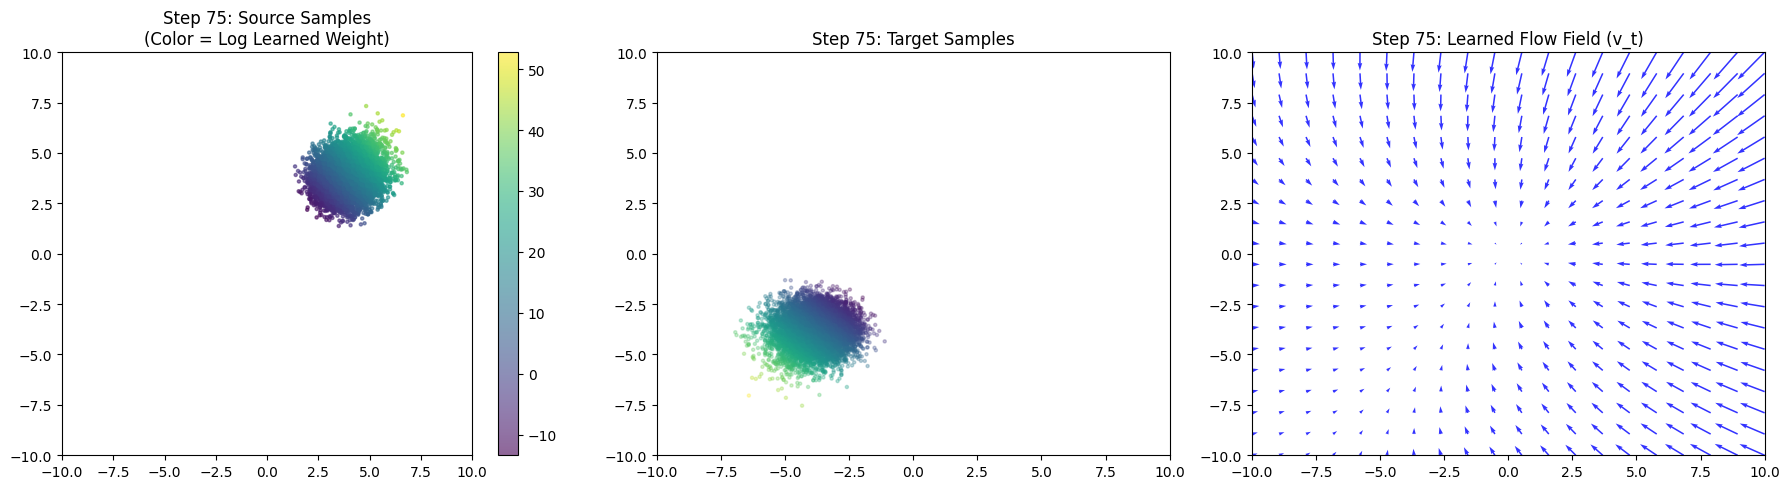

Step 75: Coupling Evaluation - MSE: 0.0056, L1: 0.0498, Corr: -0.9965
--- Mass Conservation Check ---
Mean Weight:       1.12619 (Target: 1.0)
Net Mass Flux:     0.12619 (Target: 0.0)


100%|██████████| 2/2 [00:00<00:00,  6.79it/s]


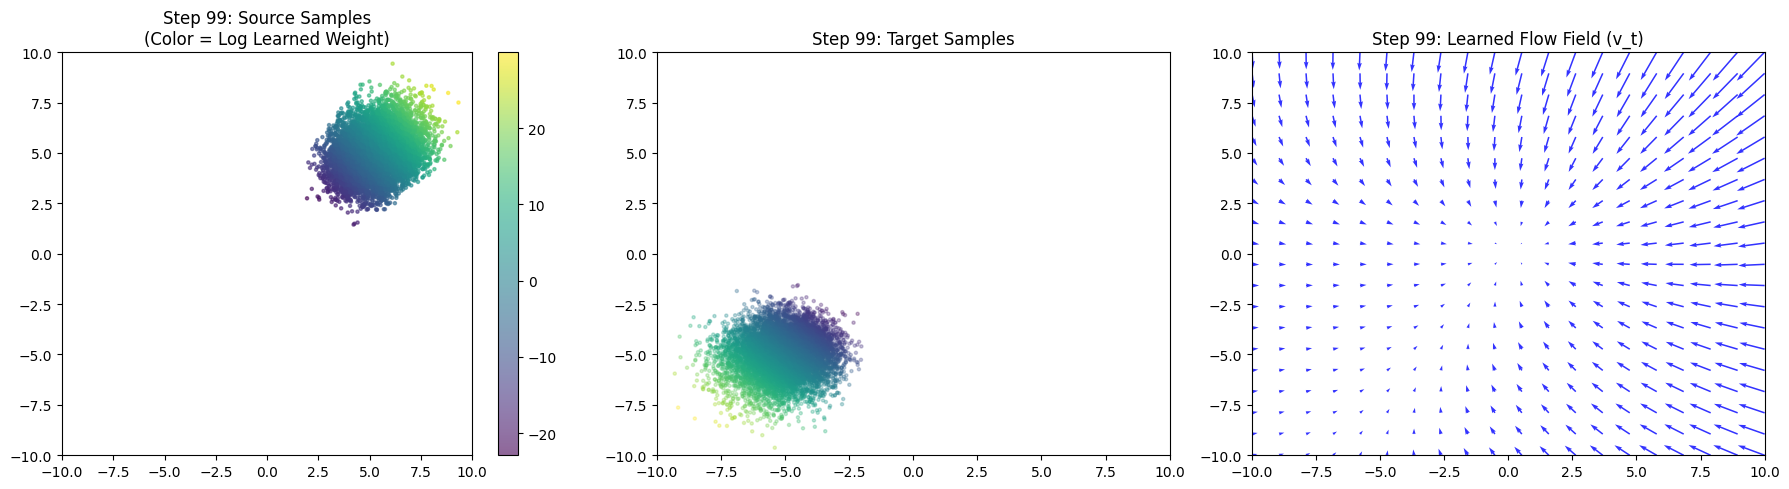

Step 99: Coupling Evaluation - MSE: 0.0276, L1: 0.1194, Corr: -0.9886
--- Mass Conservation Check ---
Mean Weight:       1.00265 (Target: 1.0)
Net Mass Flux:     0.00265 (Target: 0.0)
Training completed!
Performing final evaluation...


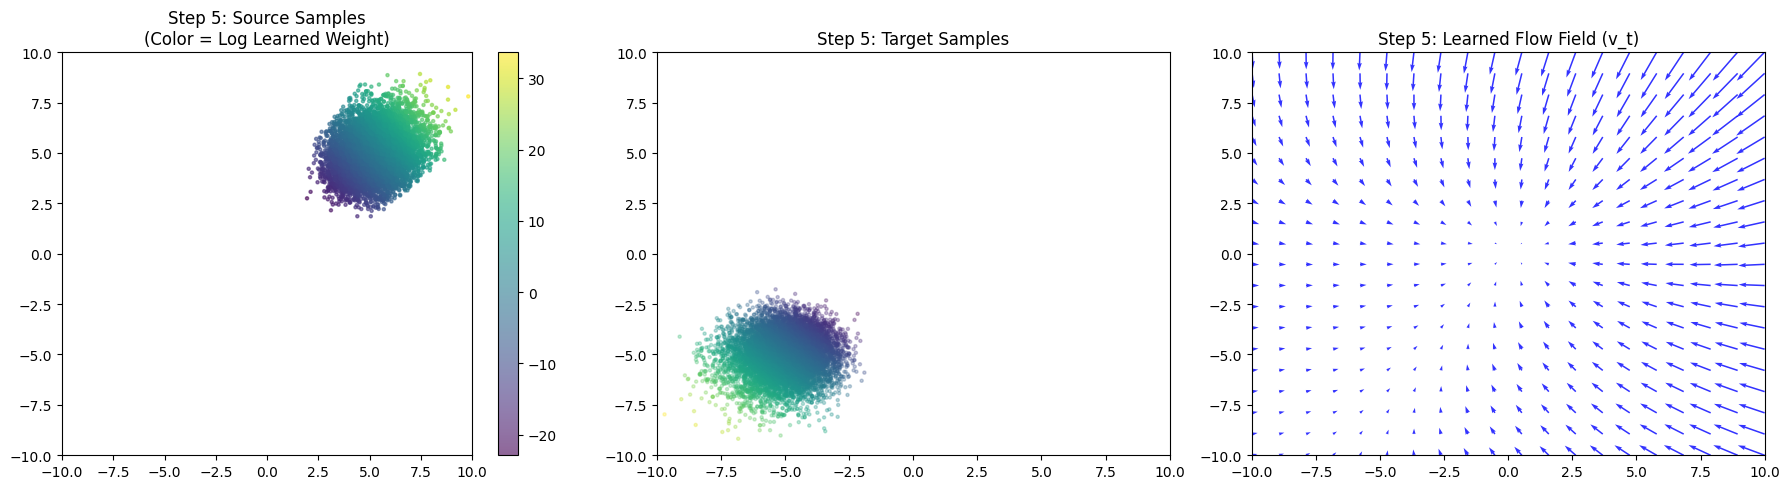

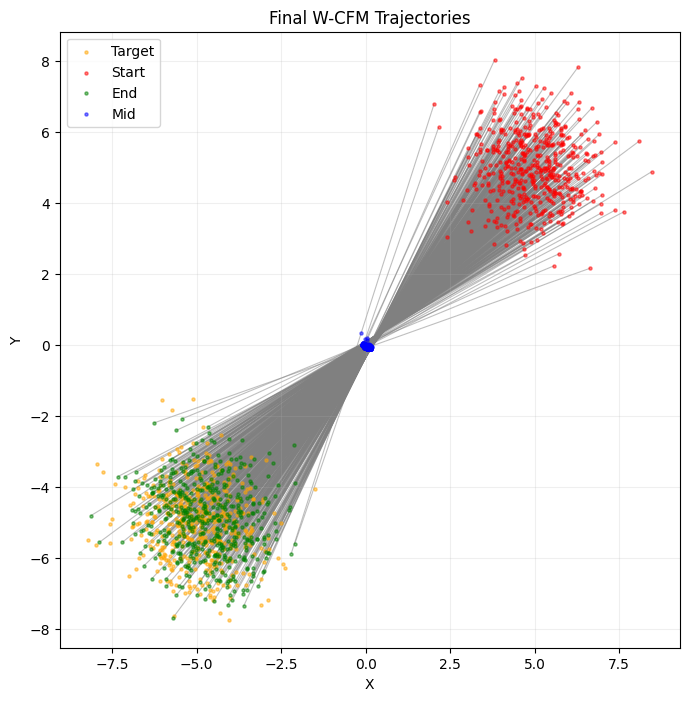

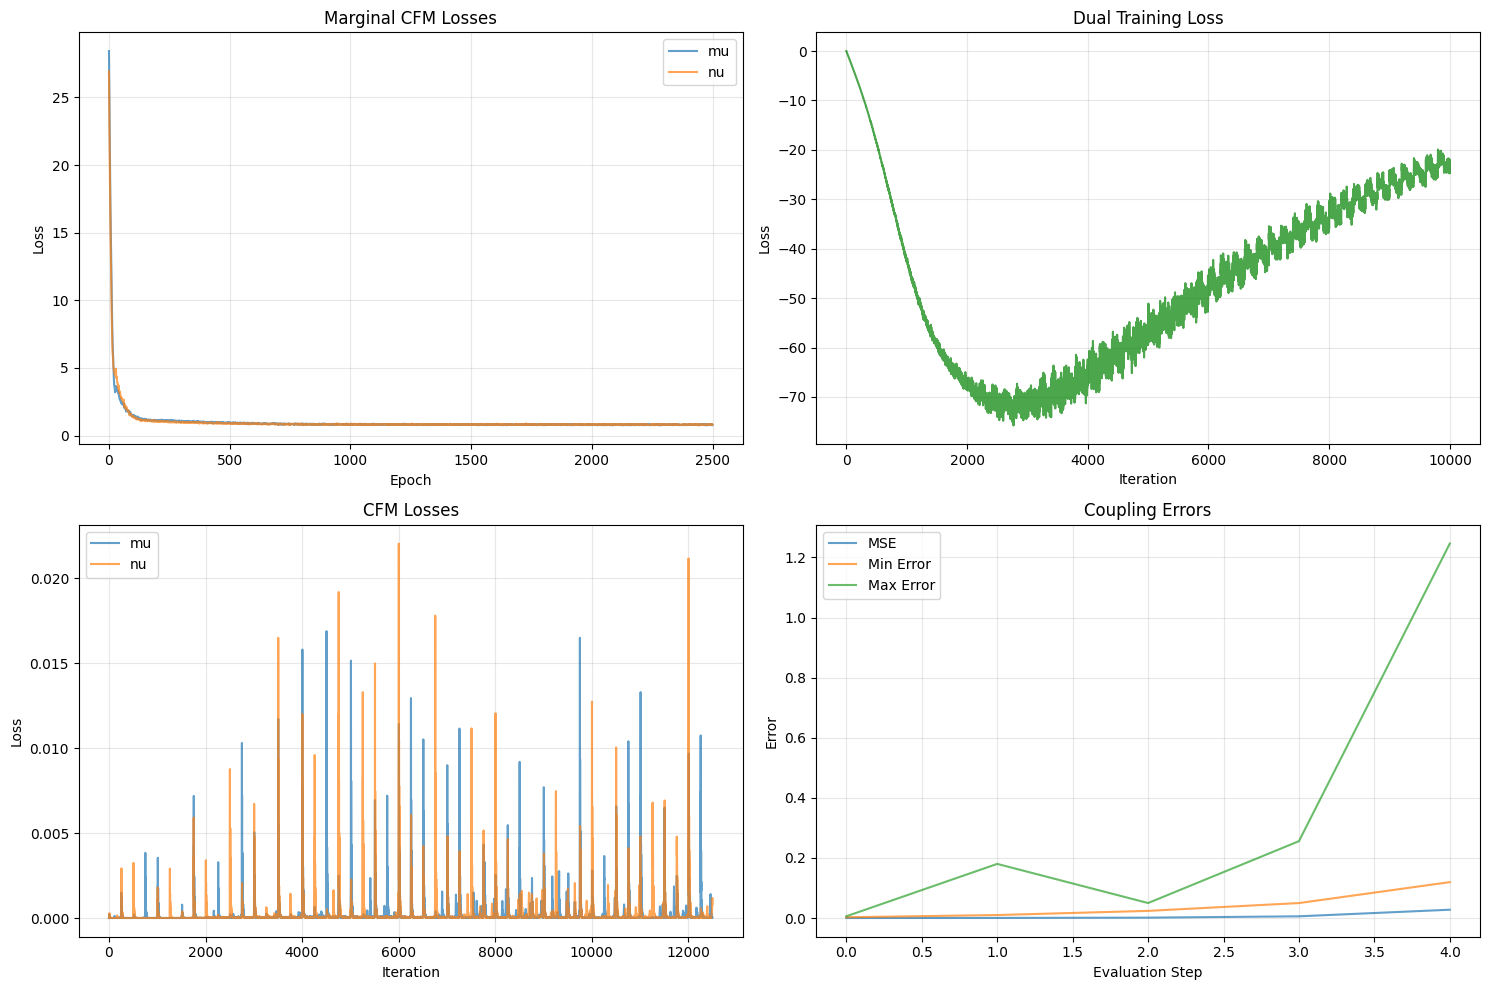

Setting up experiment...


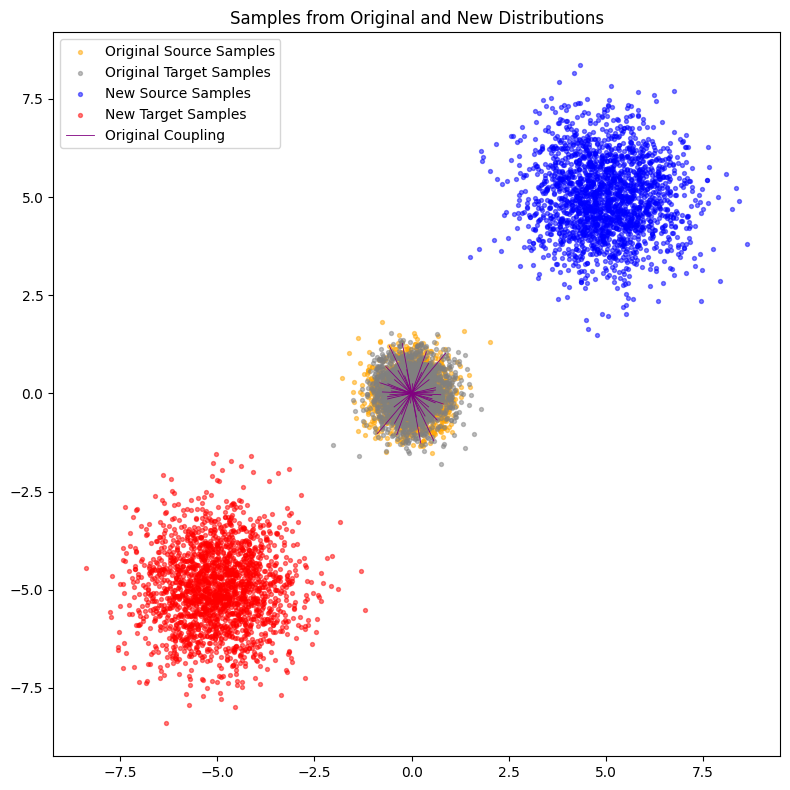

Training marginal CFM...


CFM Training Step 0:   0%|          | 0/250 [00:00<?, ?it/s]


RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

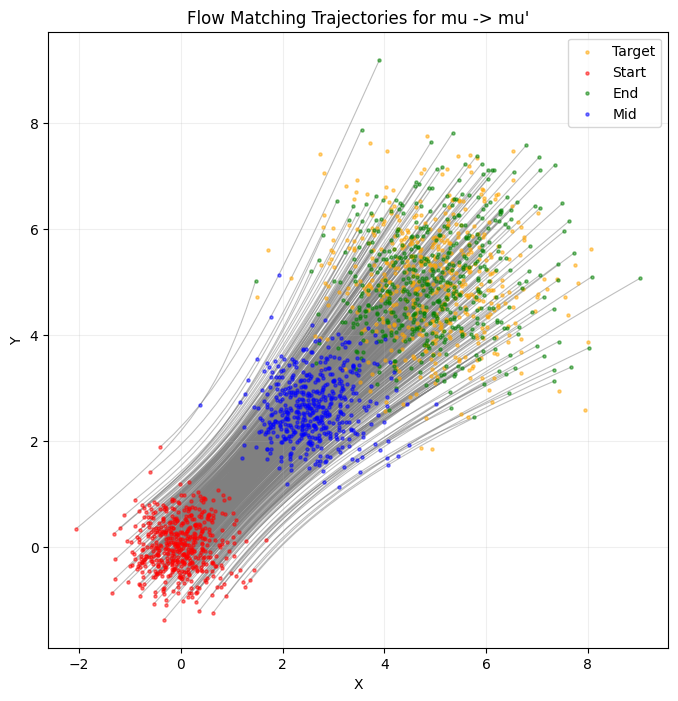

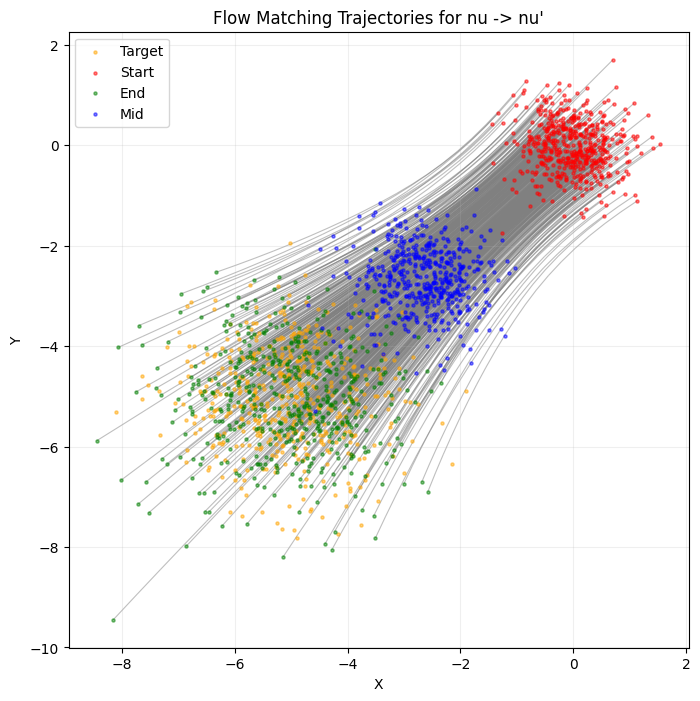

In [26]:
"""Main function to run the experiment."""
config_implicit = {
    "device": device,
    "batch_size": 2048,
    "epochs_marginal": 2500,
    "sigma": 0.1,
    "n_iterations": 100,
    "pretrained_epochs": 10000,
    "epochs_dual_per_step": 100,
    "epochs_cfm_per_step": 250,
    "dataset_size": 200_000,
    "mode": "implicit",
    "dual_lr": 1e-4,
    "cfm_lr": 5e-3,
    "gp_lambda": 0.1,
    "tau": 0.05,
}
config_explicit = {
    "device": device,
    "batch_size": 2048,
    "epochs_marginal": 2500,
    "sigma": 0.1,
    "n_iterations": 100,
    "pretrained_epochs": 10000,
    "epochs_dual_per_step": 100,
    "epochs_cfm_per_step": 250,
    "dataset_size": 200_000,
    "mode": "explicit",
    "dual_lr": 1e-4,
    "cfm_lr": 5e-3,
    "gp_lambda": 0.1,
    "tau": 0.05,
}
config_weight = {
    "device": device,
    "batch_size": 2048,
    "epochs_marginal": 2500,
    "sigma": 0.1,
    "n_iterations": 100,
    "pretrained_epochs": 10000,
    "epochs_dual_per_step": 100,
    "epochs_cfm_per_step": 250,
    "dataset_size": 200_000,
    "mode": "weight",
    "dual_lr": 1e-4,
    "cfm_lr": 5e-3,
    "gp_lambda": 0.1,
    "tau": 0.05,
}

experiment = Experiment(config_weight)
results = experiment.run()

experiment = Experiment(config_implicit)
results = experiment.run()

experiment = Experiment(config_explicit)
results = experiment.run()


print(f"Experiment saved to: {results['experiment_dir']}")

